# Задание 3. Логистическая регрессия и повторённые выбросы

Сравниваем класс 0 с классом 1. В бинарной задаче кодируем класс 0 как Y=1.
Проверяем, как кратность и удалённость одной точки влияют на линейную и
логистическую регрессии.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="ticks")
SEED = 42

In [2]:
def inspect_data(raw, features, target="class"):
    df = raw.dropna(subset=[*features, target]).copy()
    display(pd.DataFrame({
        "исходные строки": [len(raw)],
        "исходные столбцы": [raw.shape[1]],
        "исходные признаки": [raw.shape[1] - 1],
        "выбранные признаки": [len(features)],
        "классы": [raw[target].nunique()],
        "строки с пропусками, %": [100 * raw.isna().any(axis=1).mean()],
        "строки после очистки": [len(df)],
    }))
    display(pd.concat(
        [raw[target].value_counts().rename("до"), df[target].value_counts().rename("после")],
        axis=1,
    ).sort_index())
    display(df[features].describe().round(3))
    for label, subset in [("Вся выборка", df), *df.groupby(target, sort=True)]:
        display(subset[features].corr(method="pearson").round(3)
                .style.set_caption(f"Корреляция Пирсона · {label}"))
    return df

def pairplot(df, features, target="class"):
    classes = sorted(df[target].unique())
    graph = sns.pairplot(
        df, vars=features, hue=target, markers=["o", "s", "^", "D", "v", "P", "X"][:len(classes)],
        diag_kind="hist", diag_kws={"bins": 20, "element": "step", "fill": False},
        plot_kws={"alpha": 0.55, "s": 12, "linewidth": 0}, height=1.75,
    )
    graph.fig.set_dpi(95)
    plt.show()

,исходные строки,исходные столбцы,исходные признаки,выбранные признаки,классы,"строки с пропусками, %",строки после очистки
0,300,5,4,4,3,0.0,300


,до,после
class,,
0,100,100
1,100,100
2,100,100


,x1,x2,x3,x4
count,300.000,300.000,300.000,300.000
mean,-0.291,0.347,-0.279,0.376
std,1.303,1.425,1.360,1.383
min,-3.651,-2.805,-3.697,-3.302
25%,-1.233,-0.567,-1.250,-0.548
50%,-0.373,0.490,-0.405,0.459
75%,0.599,1.342,0.697,1.422
max,3.315,4.853,3.190,3.720


,x1,x2,x3,x4
x1,1.000000,0.260000,0.475000,0.321000
x2,0.260000,1.000000,0.269000,0.516000
x3,0.475000,0.269000,1.000000,0.265000
x4,0.321000,0.516000,0.265000,1.000000


,x1,x2,x3,x4
x1,1.000000,-0.016000,0.018000,-0.020000
x2,-0.016000,1.000000,-0.034000,0.137000
x3,0.018000,-0.034000,1.000000,-0.038000
x4,-0.020000,0.137000,-0.038000,1.000000


,x1,x2,x3,x4
x1,1.000000,-0.137000,-0.115000,0.108000
x2,-0.137000,1.000000,0.120000,0.044000
x3,-0.115000,0.120000,1.000000,0.071000
x4,0.108000,0.044000,0.071000,1.000000


,x1,x2,x3,x4
x1,1.000000,-0.116000,0.103000,-0.021000
x2,-0.116000,1.000000,-0.033000,0.023000
x3,0.103000,-0.033000,1.000000,-0.003000
x4,-0.021000,0.023000,-0.003000,1.000000


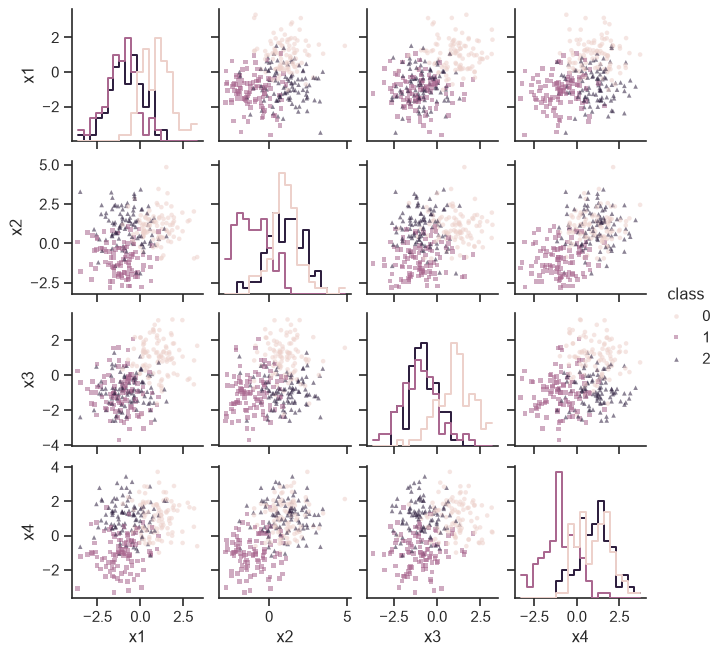

class,0,1,2
df,100,100,100
df_1_5,101,100,100
df_1_10,101,100,100
df_1_20,101,100,100
df_10_5,110,100,100
df_10_10,110,100,100
df_10_20,110,100,100
df_100_5,200,100,100
df_100_10,200,100,100
df_100_20,200,100,100


In [3]:
from sklearn.datasets import make_blobs
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import auc, roc_curve
from sklearn.model_selection import train_test_split

features = [f"x{i}" for i in range(1, 5)]
X, y = make_blobs(
    n_samples=[100] * 3,
    centers=[[1, 1, 1, 1], [-1, -1, -1, -1], [-1, 1, -1, 1]],
    cluster_std=1, random_state=SEED,
)
df = inspect_data(pd.DataFrame(X, columns=features).assign(**{"class": y}), features)
pairplot(df, features)

def add_points(data, count, distance):
    new_points = np.tile([distance, -distance, distance, -distance], (count, 1))
    extra = pd.DataFrame(new_points, columns=features).assign(**{"class": 0, "added": True})
    return pd.concat([data.assign(added=False), extra], ignore_index=True)

variants = [(0, 0), *itertools.product([1, 10, 100], [5, 10, 20])]
names = {variant: "df" if variant == (0, 0) else f"df_{variant[0]}_{variant[1]}"
         for variant in variants}
datasets = {names[variant]: add_points(df, *variant) for variant in variants}
display(pd.DataFrame({name: data["class"].value_counts()
                      for name, data in datasets.items()}).T)

## Оценка на одном тестовом наборе

Выделяем 40% исходных точек двух классов в фиксированный стратифицированный тест.
Повторённые точки добавляем в обучение, а ROC каждой модели измеряем на исходном
тесте. Это позволяет сравнивать модели на одинаковых объектах без утечки копий.
Рабочая точка соответствует вероятности 0,5. Для AUROC, sensitivity и specificity
используем 95% перцентильные интервалы по 1 000 стратифицированным репликам теста.
Полосы ROC показывают точечные интервалы TPR при фиксированных FPR.

In [4]:
source = df[df["class"].isin([0, 1])]
train, test = train_test_split(
    source, test_size=0.40, stratify=source["class"], random_state=SEED,
)
target = test["class"].eq(0).to_numpy()
test_groups = [np.flatnonzero(target == label) for label in (False, True)]
fpr_grid = np.linspace(0, 1, 101)
rng = np.random.default_rng(SEED)
bootstrap_indices = np.stack([
    np.concatenate([rng.choice(group, size=len(group)) for group in test_groups])
    for _ in range(1000)
])

def roc_summary(y, probability):
    fpr, tpr, _ = roc_curve(y, probability, drop_intermediate=False)
    predicted = probability >= 0.5
    return fpr, tpr, np.array([auc(fpr, tpr), predicted[y].mean(), (~predicted[~y]).mean()])

def plot_roc(ax, probability):
    fpr, tpr, values = roc_summary(target, probability)
    curves, metrics = [], []
    for sample in bootstrap_indices:
        boot_fpr, boot_tpr, boot_values = roc_summary(target[sample], probability[sample])
        curves.append(np.interp(fpr_grid, boot_fpr, boot_tpr))
        metrics.append(boot_values)
    lower, upper = np.percentile(curves, [2.5, 97.5], axis=0)
    conf = np.percentile(metrics, [2.5, 97.5], axis=0)
    ax.plot([0, 1], [0, 1], ":", color="0.6")
    ax.fill_between(fpr_grid, lower, upper, color="#93c5fd", alpha=0.55, label="95% CI")
    ax.plot(fpr, tpr, c="#1d4ed8", label=f"AUROC {values[0]:.3f}")
    ax.errorbar(1 - values[2], values[1],
                xerr=np.maximum(0, np.array([[conf[1, 2] - values[2]], [values[2] - conf[0, 2]]])),
                yerr=np.maximum(0, np.array([[values[1] - conf[0, 1]], [conf[1, 1] - values[1]]])),
                fmt="o", c="#b91c1c", capsize=3, label="Порог 0,5")
    ax.set(xlabel="1 − specificity", ylabel="sensitivity", xlim=(-0.04, 1.04), ylim=(-0.04, 1.04))
    ax.legend(fontsize=8, loc="lower right")
    return np.column_stack([values, conf.T]).ravel()

experiments = {}
equations = []
logdfs = {}
for variant in variants:
    name = names[variant]
    training = add_points(train, *variant)
    all_points = datasets[name].loc[datasets[name]["class"].isin([0, 1])]
    y_train = training["class"].eq(0).astype(int).to_numpy()
    multilinear = LinearRegression().fit(training[features], y_train)
    equations.append([name, multilinear.intercept_, *multilinear.coef_])
    projected = multilinear.predict(all_points[features])
    log_name = "log" + name
    logdfs[log_name] = pd.DataFrame({
        "X": projected, "Y": all_points["class"].eq(0).astype(int).to_numpy(),
    })
    experiments[name] = (training, all_points, y_train, multilinear)
display(pd.DataFrame(equations, columns=["датасет", "b0", *features]).set_index("датасет").round(4))
display(logdfs["logdf_100_20"].head())

,b0,x1,x2,x3,x4
датасет,,,,,
df,0.4980,0.1316,0.0977,0.0771,0.0937
df_1_5,0.5002,0.1414,0.0893,0.0883,0.0818
df_1_10,0.4988,0.1379,0.0924,0.0842,0.0861
df_1_20,0.4982,0.1334,0.0962,0.0790,0.0915
df_10_5,0.5019,0.1494,0.0825,0.0974,0.0721
df_10_10,0.4990,0.1392,0.0913,0.0858,0.0844
df_10_20,0.4982,0.1335,0.0962,0.0792,0.0914
df_100_5,0.5023,0.1510,0.0812,0.0992,0.0702
df_100_10,0.4990,0.1394,0.0911,0.0860,0.0842


,X,Y
0,0.113424,0
1,0.866322,1
2,0.302004,0
3,-0.281458,0
4,-0.317883,0


## Простые регрессии на x1 и на многомерном прогнозе X

Для каждого варианта строим две пары графиков. В первой паре X — исходный признак
x1, во второй X — прогноз множественной линейной регрессии, коэффициенты которой
приведены выше. Линии оцениваются на обучении, показаны все исходные точки двух
классов. Кратность добавленного выброса дана в легенде.

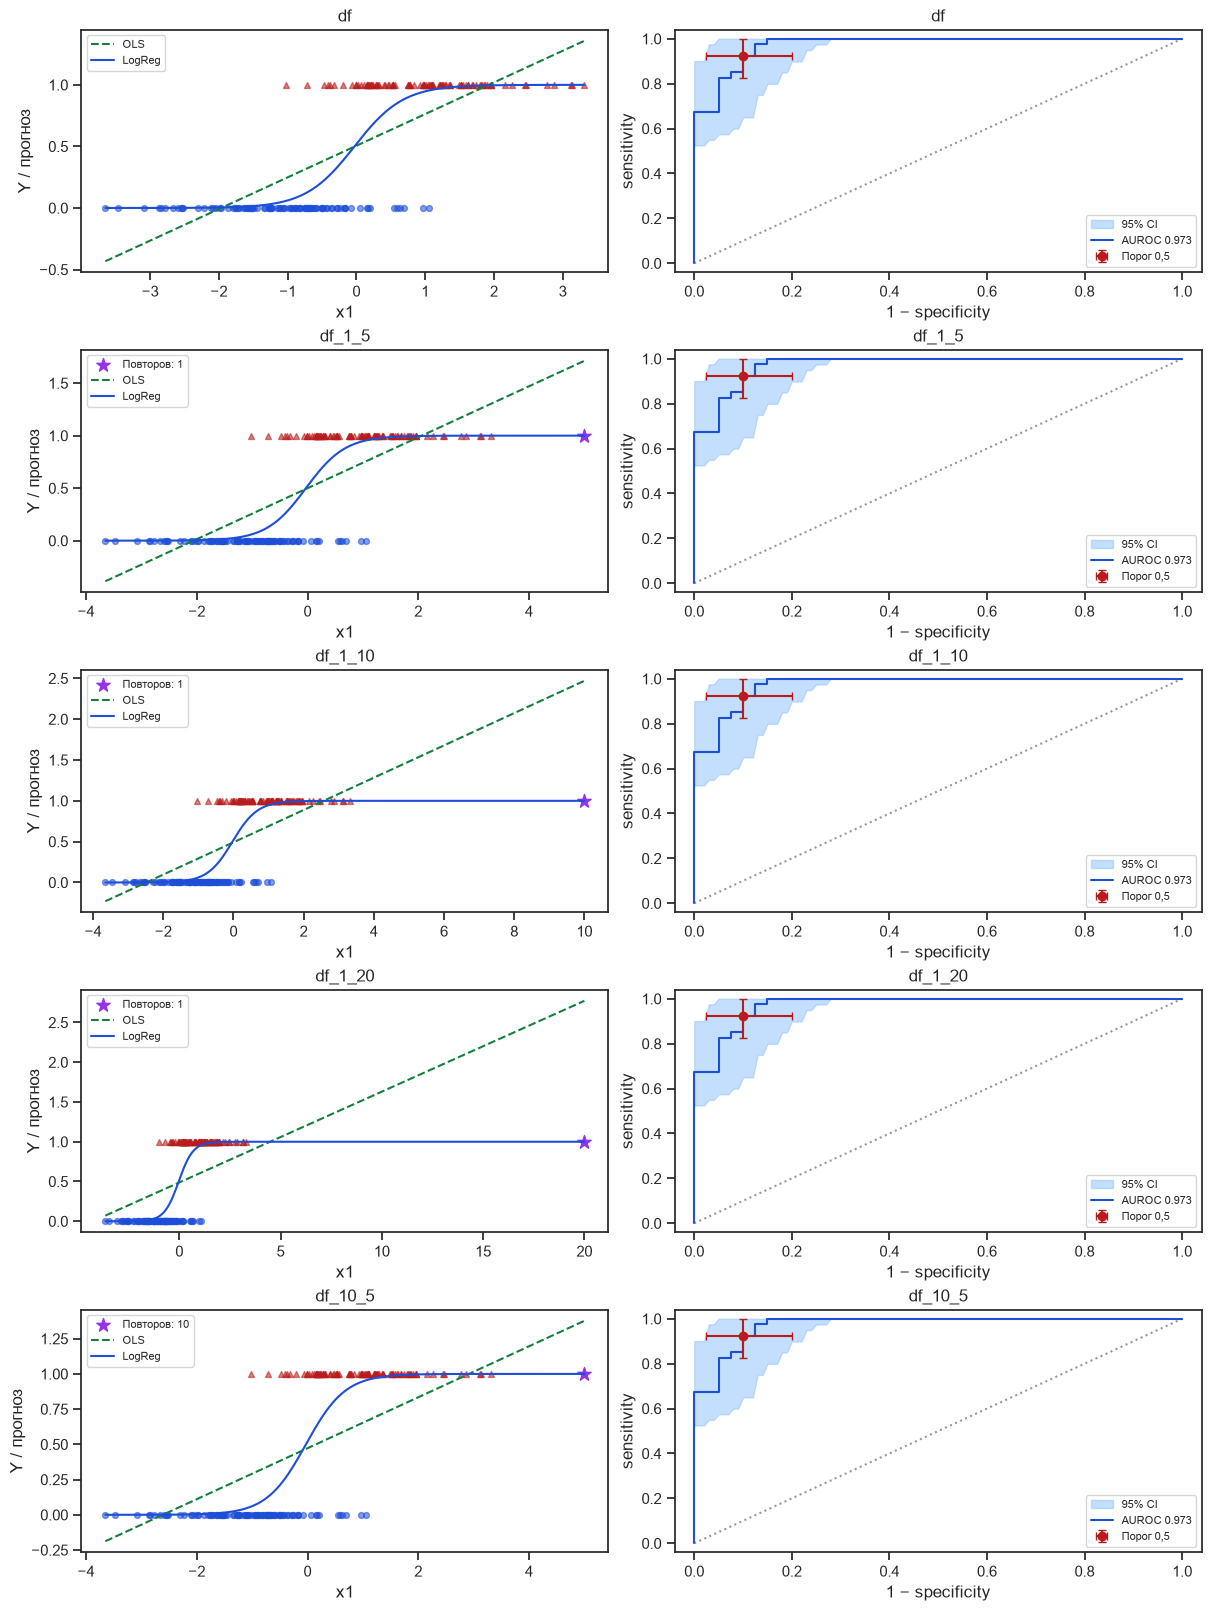

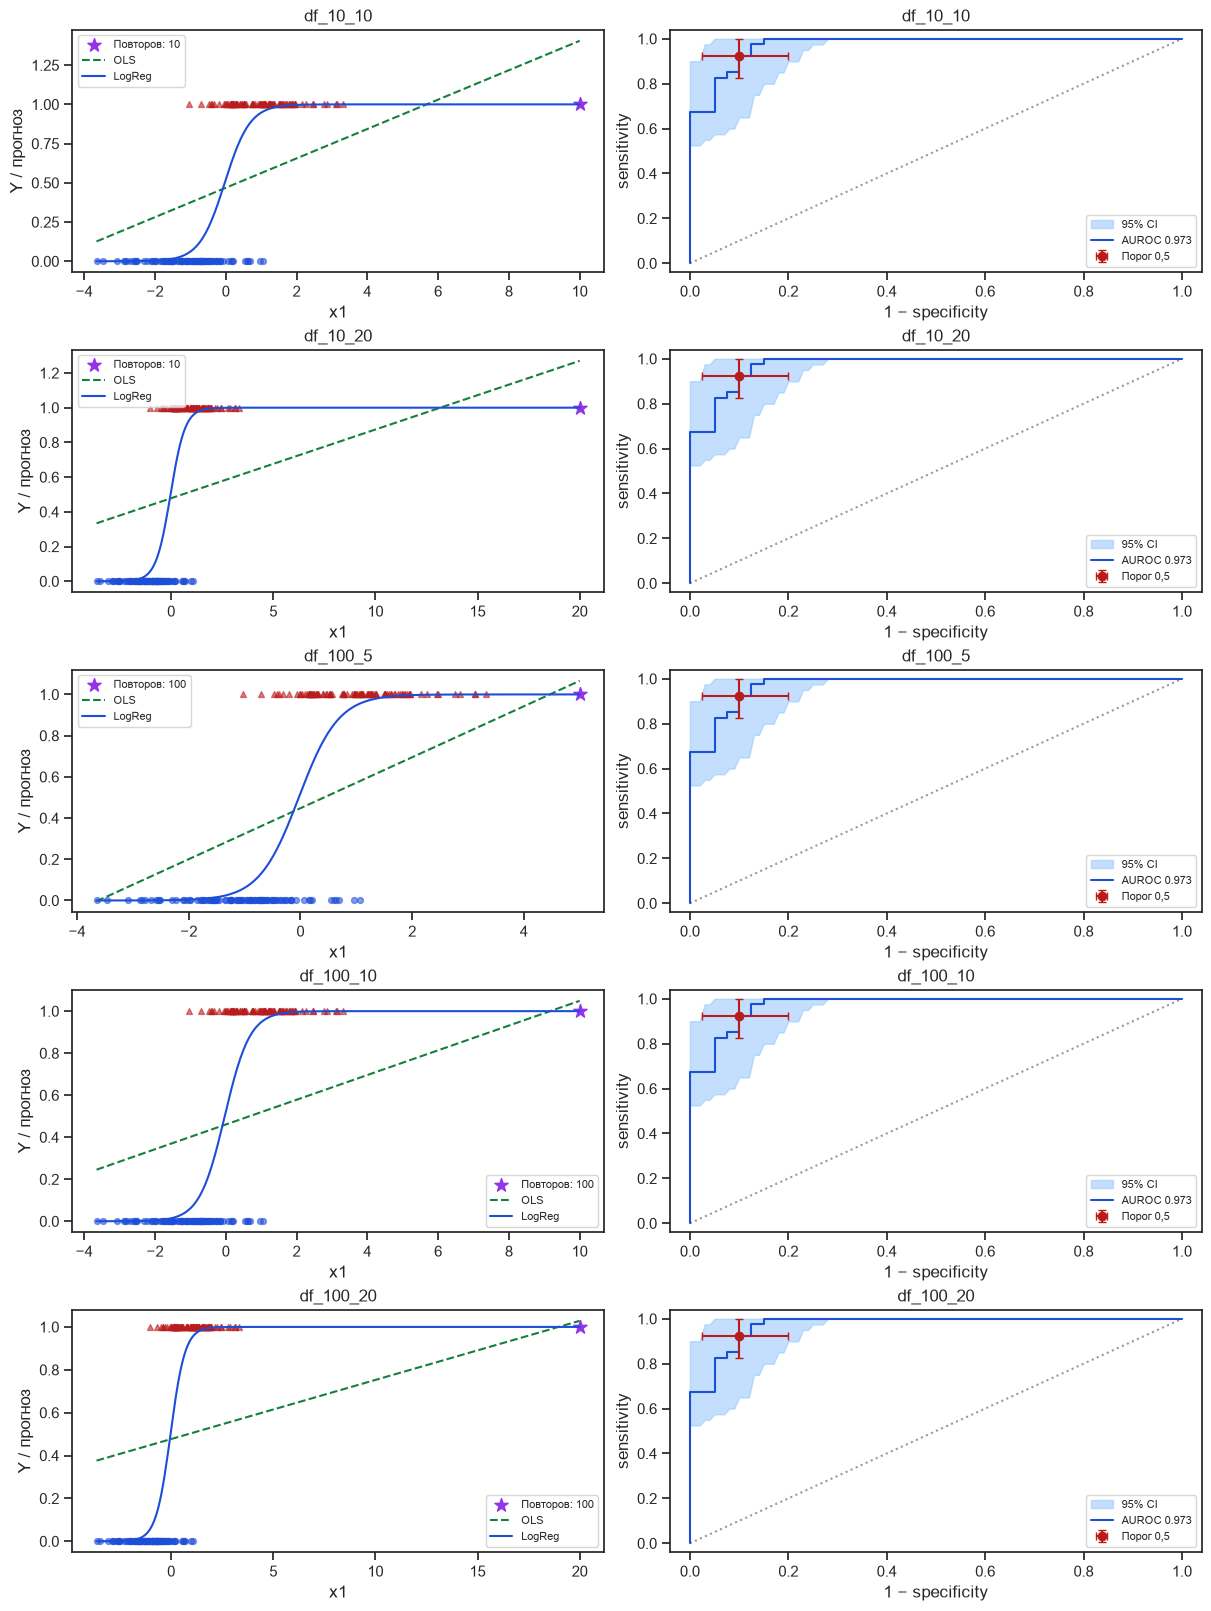

,набор,AUROC,"ROC 2,5%","ROC 97,5%",sensitivity,"sens 2,5%","sens 97,5%",specificity,"spec 2,5%","spec 97,5%"
0,df,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975
1,df_1_5,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975
2,df_1_10,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975
3,df_1_20,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975
4,df_10_5,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975
5,df_10_10,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975
6,df_10_20,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975
7,df_100_5,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975
8,df_100_10,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975
9,df_100_20,0.973,0.938,0.994,0.925,0.825,1.0,0.9,0.8,0.975


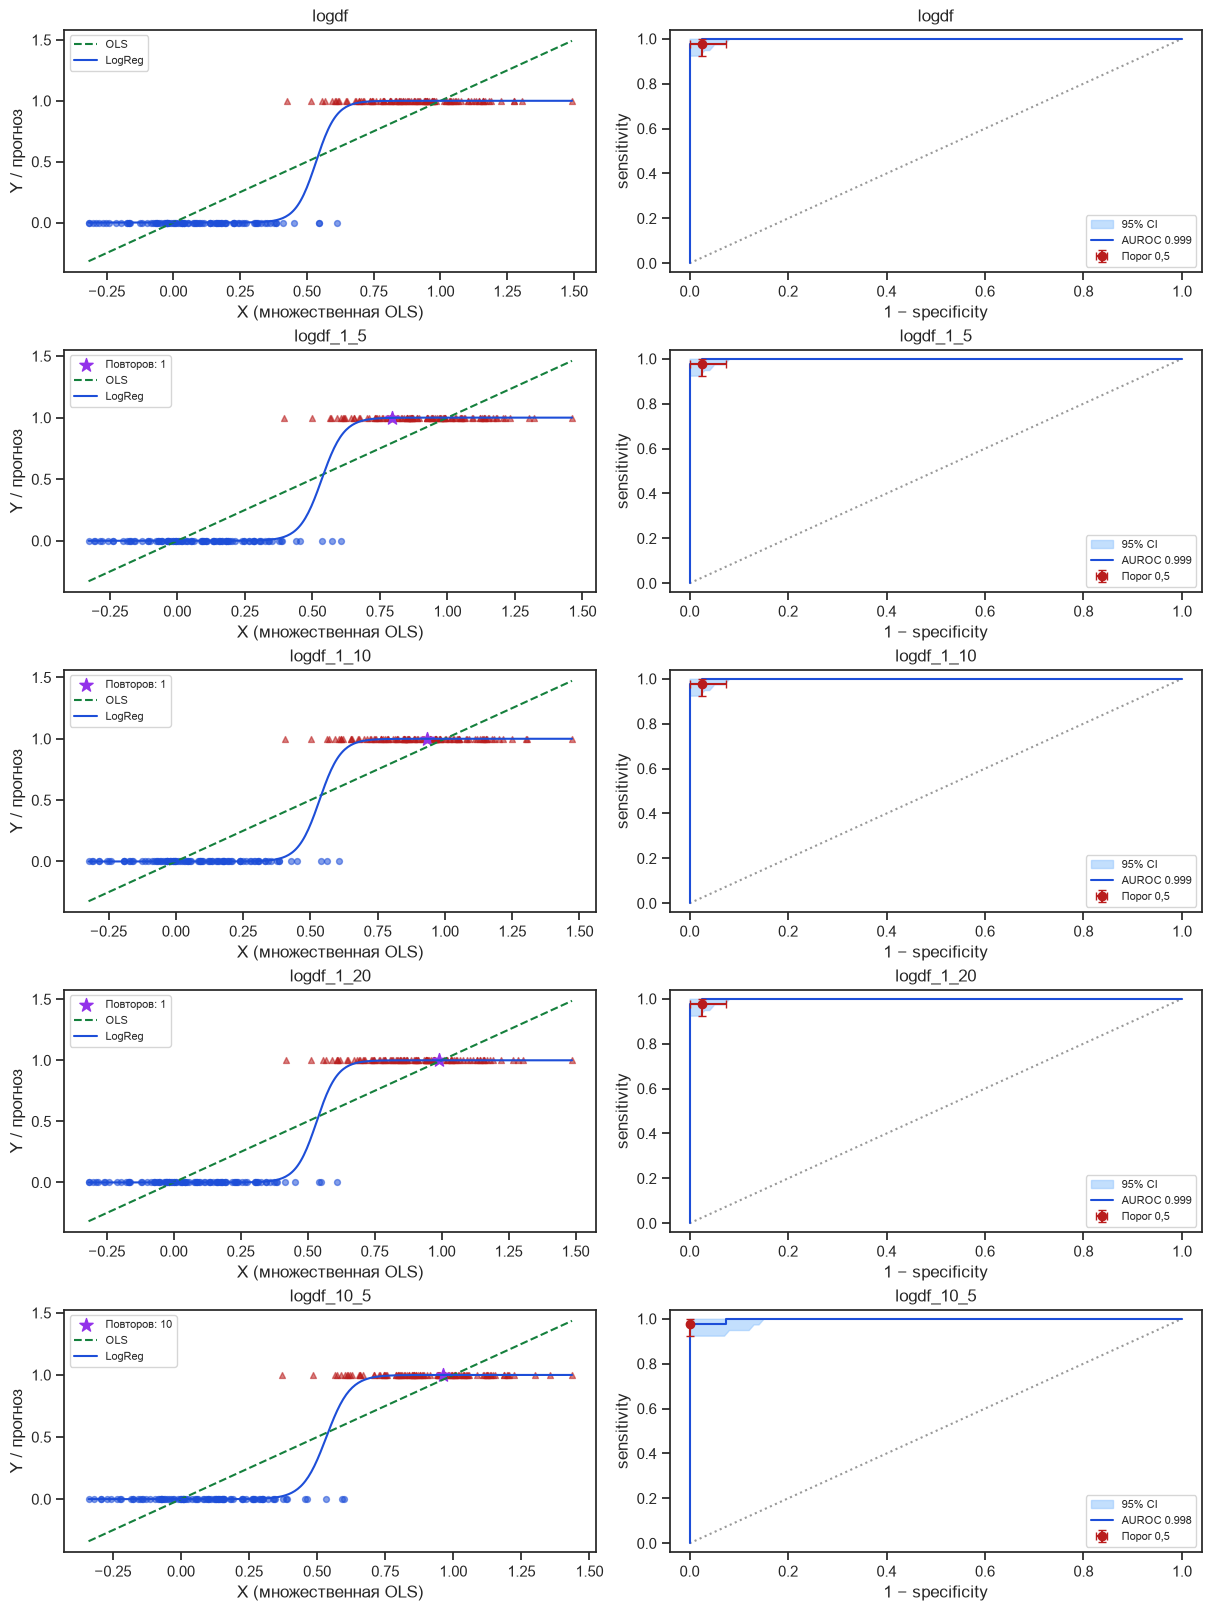

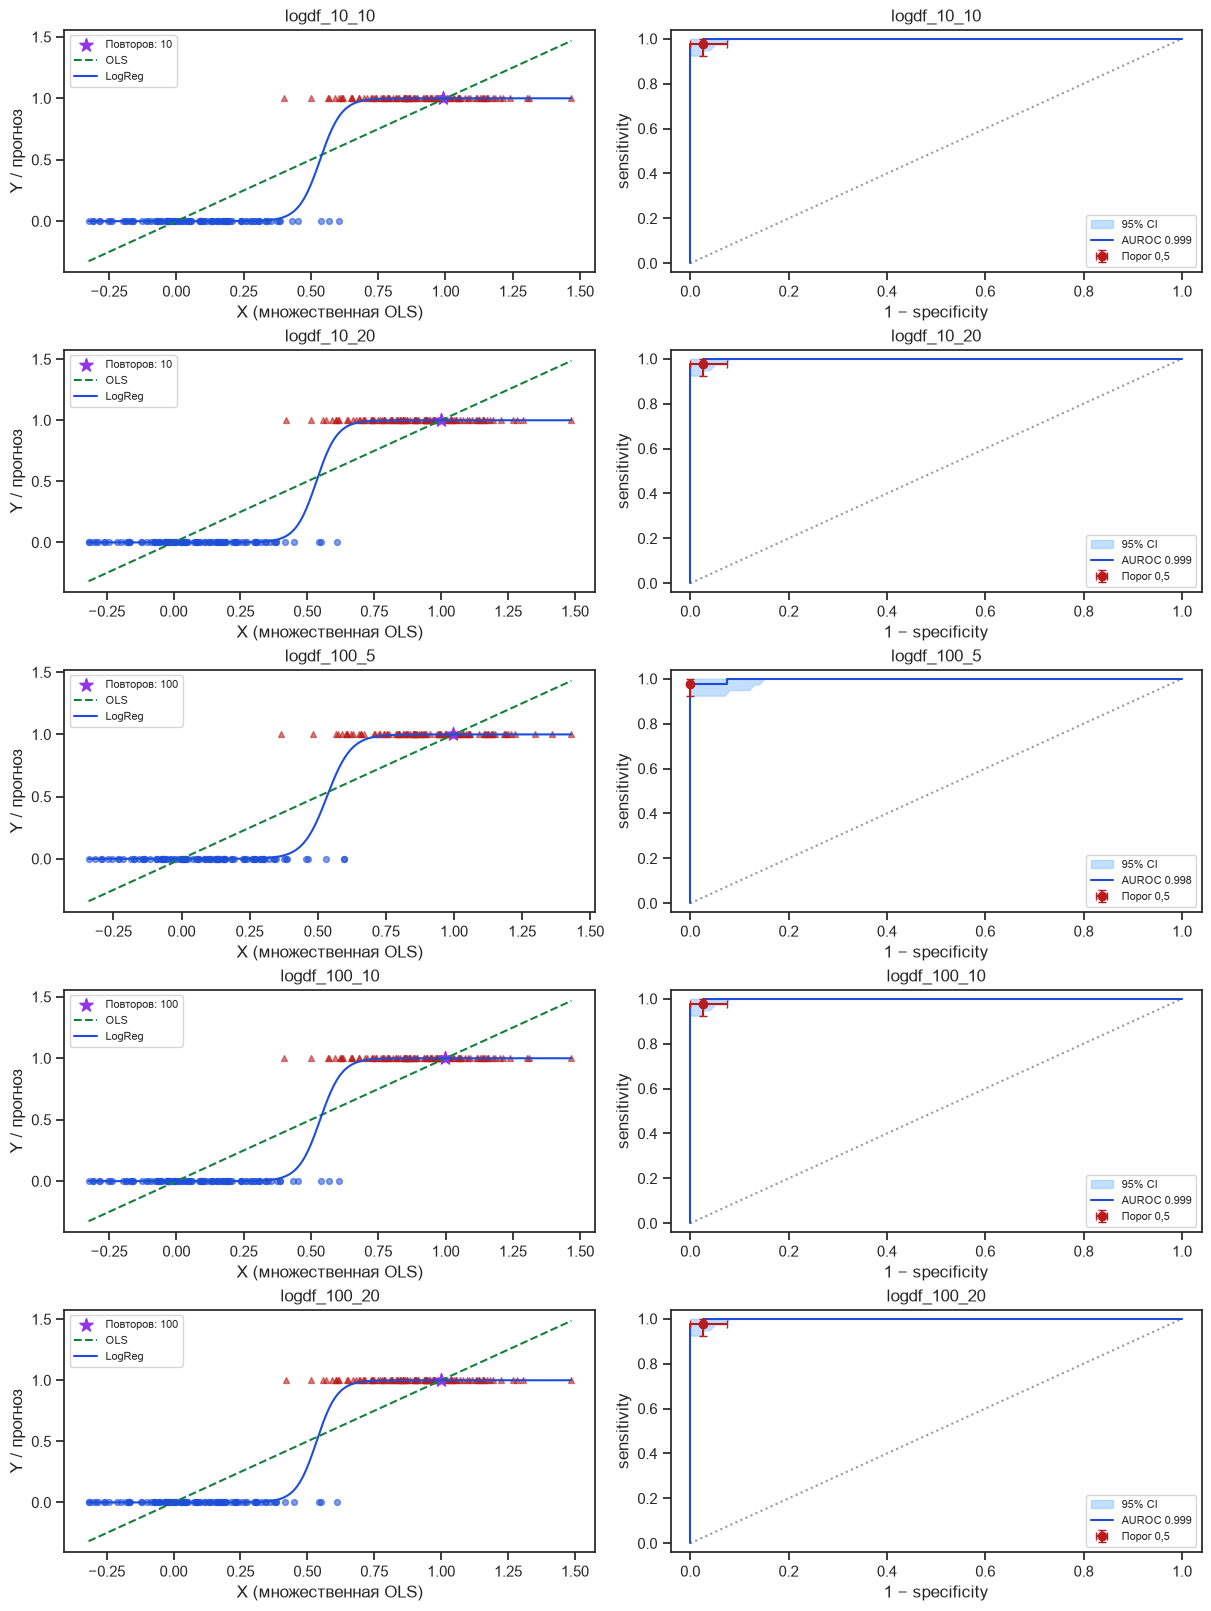

,набор,AUROC,"ROC 2,5%","ROC 97,5%",sensitivity,"sens 2,5%","sens 97,5%",specificity,"spec 2,5%","spec 97,5%"
0,logdf,0.999,0.996,1.0,0.975,0.925,1.0,0.975,0.925,1.0
1,logdf_1_5,0.999,0.996,1.0,0.975,0.925,1.0,0.975,0.925,1.0
2,logdf_1_10,0.999,0.996,1.0,0.975,0.925,1.0,0.975,0.925,1.0
3,logdf_1_20,0.999,0.996,1.0,0.975,0.925,1.0,0.975,0.925,1.0
4,logdf_10_5,0.998,0.992,1.0,0.975,0.925,1.0,1.000,1.000,1.0
5,logdf_10_10,0.999,0.996,1.0,0.975,0.925,1.0,0.975,0.925,1.0
6,logdf_10_20,0.999,0.996,1.0,0.975,0.925,1.0,0.975,0.925,1.0
7,logdf_100_5,0.998,0.992,1.0,0.975,0.925,1.0,1.000,1.000,1.0
8,logdf_100_10,0.999,0.996,1.0,0.975,0.925,1.0,0.975,0.925,1.0
9,logdf_100_20,0.999,0.996,1.0,0.975,0.925,1.0,0.975,0.925,1.0


In [5]:
fits = {}

def study_regressions(projected):
    rows = []
    for start in range(0, len(variants), 5):
        fig, axes = plt.subplots(5, 2, figsize=(12, 16), layout="constrained")
        for variant, (fit_ax, roc_ax) in zip(variants[start:start + 5], axes):
            name = names[variant]
            training, all_points, y_train, multilinear = experiments[name]
            if projected:
                name = "log" + name
                x_train = multilinear.predict(training[features])
                x_test = multilinear.predict(test[features])
                x_all = logdfs[name]["X"].to_numpy()
            else:
                x_train, x_test, x_all = (data["x1"].to_numpy() for data in (training, test, all_points))
            linear = LinearRegression().fit(x_train[:, None], y_train)
            logistic = LogisticRegression(C=1e6, max_iter=1000).fit(x_train[:, None], y_train)
            fits[name] = logistic
            z = np.linspace(x_all.min(), x_all.max(), 320)[:, None]
            added = all_points["added"].to_numpy()
            y_all = all_points["class"].eq(0).to_numpy()
            for label, marker, color in [(False, "o", "#1d4ed8"), (True, "^", "#b91c1c")]:
                mask = (y_all == label) & ~added
                fit_ax.scatter(x_all[mask], y_all[mask].astype(int), c=color, marker=marker, s=18, alpha=.55)
            if added.any():
                fit_ax.scatter(x_all[added][0], 1, marker="*", c="#9333ea", s=100, label=f"Повторов: {added.sum()}")
            fit_ax.plot(z.ravel(), linear.predict(z), "--", c="#15803d", label="OLS")
            fit_ax.plot(z.ravel(), logistic.predict_proba(z)[:, 1], c="#1d4ed8", label="LogReg")
            fit_ax.set(xlabel="X (множественная OLS)" if projected else "x1",
                       ylabel="Y / прогноз", title=name)
            fit_ax.legend(fontsize=8)
            roc_ax.set_title(name)
            rows.append([name, *plot_roc(roc_ax, logistic.predict_proba(x_test[:, None])[:, 1])])
        plt.show()
    display(pd.DataFrame(rows, columns=["набор", "AUROC", "ROC 2,5%", "ROC 97,5%",
                                       "sensitivity", "sens 2,5%", "sens 97,5%",
                                       "specificity", "spec 2,5%", "spec 97,5%"]).round(3))

study_regressions(projected=False)
study_regressions(projected=True)

## Срезы четырёхмерной модели для df_10_5

Для каждой пары фиксируем остальные признаки на медианах обучающей выборки.
Линии OLS показывают уровни прогноза 0,25, 0,5 и 0,75, цвет — вероятность класса 0
после LogReg. Толстая линия — граница p=0,5. Нанесённые точки показывают свои
фактические координаты в выбранной паре, поэтому их скрытые координаты могут
отличаться от фиксированных медиан.

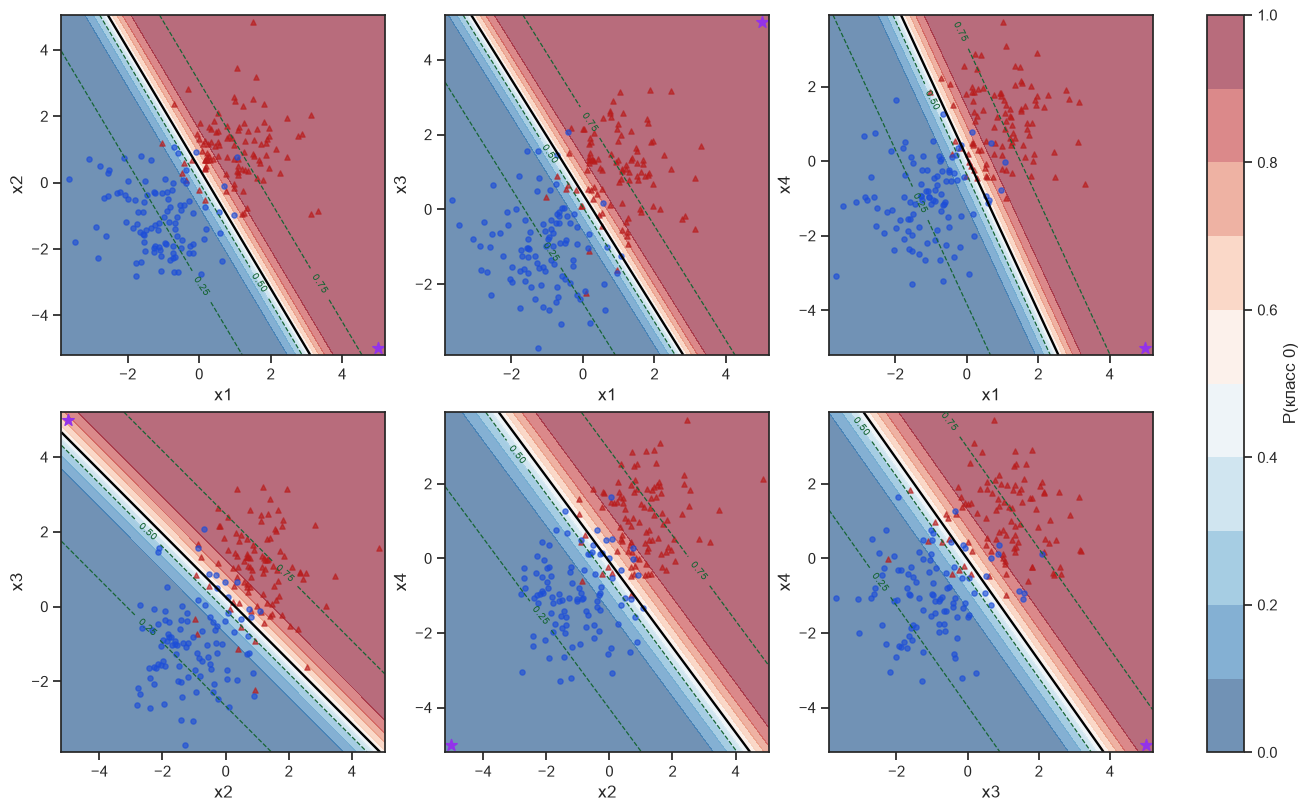

In [6]:
name = "df_10_5"
training, all_points, _, multilinear = experiments[name]
logistic = fits["log" + name]
fixed = training[features].median()
fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout="constrained")
for ax, pair in zip(axes.flat, itertools.combinations(features, 2)):
    first, second = pair
    xx, yy = np.meshgrid(*(np.linspace(all_points[f].min() - .2, all_points[f].max() + .2, 140)
                           for f in pair))
    positions = pd.DataFrame(np.tile(fixed.to_numpy(), (xx.size, 1)), columns=features)
    positions[first], positions[second] = xx.ravel(), yy.ravel()
    linear_values = multilinear.predict(positions)
    probability = logistic.predict_proba(linear_values[:, None])[:, 1].reshape(xx.shape)
    color = ax.contourf(xx, yy, probability, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=.6)
    ols_levels = ax.contour(xx, yy, linear_values.reshape(xx.shape), levels=[.25, .5, .75],
                            colors="#166534", linewidths=.9, linestyles="--")
    ax.clabel(ols_levels, fontsize=7)
    ax.contour(xx, yy, probability, levels=[.5], colors="black", linewidths=1.7)
    for label, marker, color_name in [(0, "^", "#b91c1c"), (1, "o", "#1d4ed8")]:
        data = all_points[all_points["class"].eq(label) & ~all_points["added"]]
        ax.scatter(data[first], data[second], c=color_name, marker=marker, s=14, alpha=.65)
    added = all_points.loc[all_points["added"]].iloc[0]
    ax.scatter(added[first], added[second], c="#9333ea", marker="*", s=75)
    ax.set(xlabel=first, ylabel=second)
fig.colorbar(color, ax=axes, label="P(класс 0)")
plt.show()

Выброс расположен в правом хвосте x1 и имеет положительную метку. Он влияет на
наклон OLS тем сильнее, чем дальше расположен. Многомерная регрессия также
использует знаки остальных координат, поэтому по её прогнозу виден эффект
направления выброса, которого нет при работе только с x1.

На фиксированном тесте AUROC по x1 во всех вариантах равен 0,973.
Логистическая регрессия сохранила положительный коэффициент, поэтому изменение
линии вероятности не изменило порядок точек. При использовании всех четырёх
признаков AUROC составляет 0,998–0,999, а при B=5 и A=10 или A=100 на данном
тесте также меняется специфичность при пороге 0,5.